# LLSMF2901 - Technological Project

This report details the initial phase of our Operational Research project, focusing on constructing a high-performing financial portfolio.

The objective is to apply the Markowitz model of risk to a selection of companies from the BEL20 index on the period 2024-2025.

Specifically, we will determine:
- The average retruns
- The covariance Matrix of the returns of the 20 assets
- The efficient frontier under no constraints
- The efficient frontier under the constraint of no short selling
- Identify low risk and tangent portfolios
- Additionally, we will explore the construction of a well-performing (long only) portfolio limited to just five assets.

## Import and data cleaning

In this section, we import the necessary libraries for data manipulation, numerical operations, plotting, and optimization.

we then load the stock price data from a CSV file after cleaning and refomatting.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize

#create a dataframe with prices
df = pd.read_csv('BEL20_2025_reformatted.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')

#create a dataframe with returns
returns = df.pct_change().dropna()
returns.head()

#List of tickers
tickers = df.columns


### Risk free rate

We assume a risk free rate of 2%


In [ ]:
rf = 0.02

## Data computing

### Price visualisaition

This code generates a series of plots, one for each ticker, showing the historical price movements over time, which helps in visualizing the individual stock price trends.

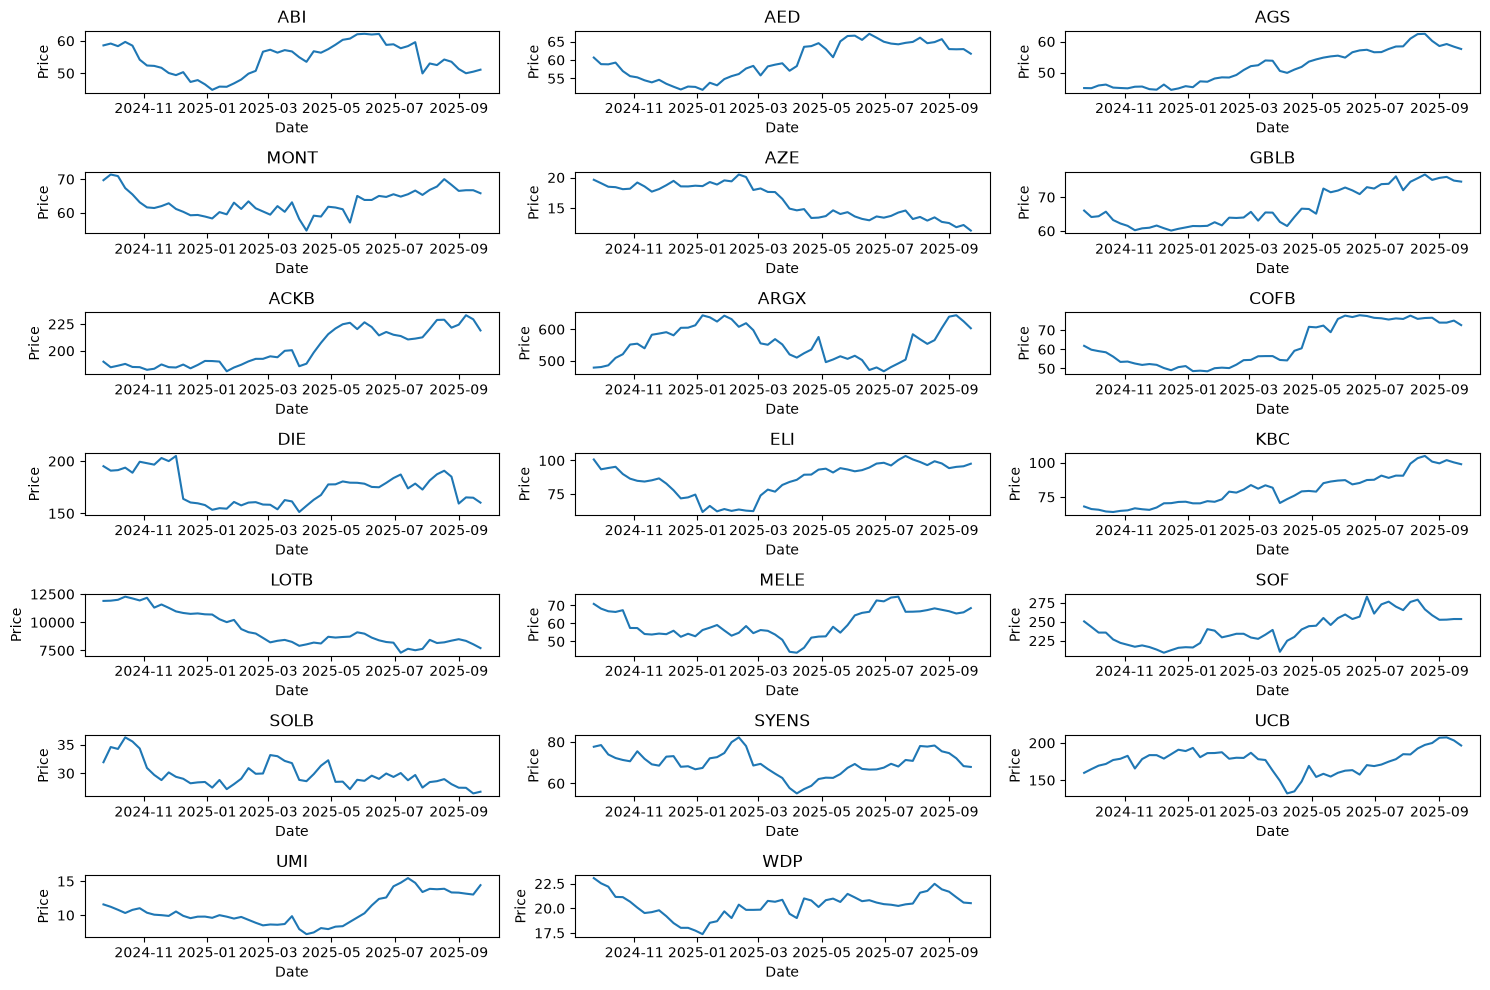

In [ ]:
plt.figure(figsize=(15, 10))

for i, ticker in enumerate(tickers):
    plt.subplot(7, 3, i + 1)
    plt.plot(df[ticker])
    plt.title(f'{ticker}')
    plt.xlabel('Date')
    plt.ylabel('Price')

plt.tight_layout()
plt.show()

### Returns & Risk evaluation

In [ ]:
#Mean returns
annual_returns = returns.mean() * 52
annual_returns.head()

ABI    -0.096478
AED     0.033936
AGS     0.258194
MONT   -0.024097
AZE    -0.499720
dtype: float64

In [ ]:
#Std  / Volatility
annual_vol = returns.std() * np.sqrt(52)
annual_vol.head()

ABI     0.282333
AED     0.187291
AGS     0.147693
MONT    0.263530
AZE     0.308894
dtype: float64

### Correlation Matrix

The correlation matrix shows the pairwise correlation coefficients between the returns of different stocks, indicating how their movements are related.

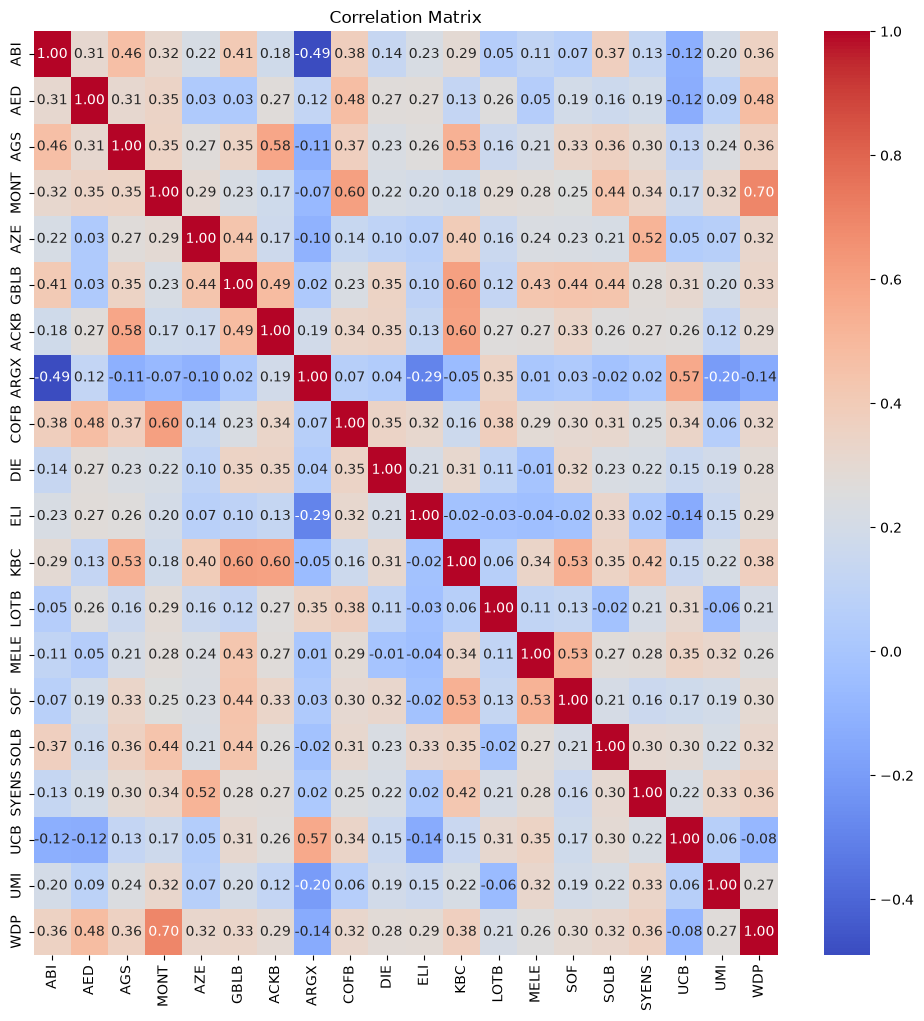

In [ ]:
corr_matrix = returns.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

### Individual sharpe ratios

The Sharpe ratio is a measure of risk-adjusted return, indicating the amount of excess return earned per unit of risk (volatility).

In [ ]:
sharp_ratios = (annual_returns - rf) / annual_vol
sharp_ratios.head()

ABI    -0.412557
AED     0.074409
AGS     1.612758
MONT   -0.167332
AZE    -1.682519
dtype: float64

##

---

## 1. Covariance Matrix

The covariance matrix is a measure of how much two assets move together, it captures the relationships between assets.
The diagonal elements of the covariance matrix represent the variances of the individual assets.

In [ ]:
cov_matrix = returns.cov() * 52

,ABI,AED,AGS,MONT,AZE,GBLB,ACKB,ARGX,COFB,DIE,ELI,KBC,LOTB,MELE,SOF,SOLB,SYENS,UCB,UMI,WDP
ABI,0.079712,0.016489,0.019380,0.023541,0.018850,0.022215,0.009343,-0.045124,0.030407,0.012274,0.022681,0.020722,0.003918,0.012220,0.005367,0.034220,0.011446,-0.011385,0.024644,0.023158
AED,0.016489,0.035078,0.008536,0.017176,0.001850,0.001049,0.009195,0.007040,0.025091,0.016122,0.018215,0.005910,0.012419,0.003915,0.009648,0.009958,0.011128,-0.007931,0.006988,0.020695
AGS,0.019380,0.008536,0.021813,0.013549,0.012256,0.009970,0.015480,-0.005473,0.015510,0.010885,0.013866,0.019674,0.005959,0.011988,0.013032,0.017451,0.013590,0.006348,0.015300,0.012352
MONT,0.023541,0.017176,0.013549,0.069448,0.023887,0.011474,0.008339,-0.005858,0.044540,0.018182,0.018656,0.011850,0.019413,0.028213,0.017645,0.037950,0.027082,0.015582,0.037044,0.042421
AZE,0.018850,0.001850,0.012256,0.023887,0.095416,0.026246,0.009531,-0.010370,0.012521,0.009999,0.007586,0.030816,0.012294,0.028355,0.018941,0.021465,0.048952,0.005266,0.009011,0.022945
GBLB,0.022215,0.001049,0.009970,0.011474,0.026246,0.037340,0.017053,0.001528,0.012444,0.021910,0.006647,0.029114,0.006110,0.032481,0.022774,0.027267,0.016290,0.020556,0.016870,0.014836
ACKB,0.009343,0.009195,0.015480,0.008339,0.009531,0.017053,0.032835,0.011179,0.017107,0.020113,0.008436,0.027046,0.012266,0.019067,0.016053,0.015299,0.014997,0.016389,0.009126,0.012158
ARGX,-0.045124,0.007040,-0.005473,-0.005858,-0.010370,0.001528,0.011179,0.106322,0.006268,0.004514,-0.034004,-0.004394,0.029098,0.000831,0.002819,-0.002481,0.001994,0.062917,-0.028857,-0.010322
COFB,0.030407,0.025091,0.015510,0.044540,0.012521,0.012444,0.017107,0.006268,0.079407,0.031341,0.031719,0.011451,0.027153,0.031332,0.022654,0.028659,0.021184,0.032729,0.007314,0.020979
DIE,0.012274,0.016122,0.010885,0.018182,0.009999,0.021910,0.020113,0.004514,0.031341,0.102717,0.024017,0.025189,0.009205,-0.000902,0.027341,0.023851,0.021491,0.016771,0.026139,0.020895


## 2. Unconstrained Efficient Frontier


### Risk-return Trade off

This plot visualizes the risk-return trade-off for individual stocks, showing their annualized volatility against their annualized returns. This gives a visual representation of how each stock performs in terms of risk and return.

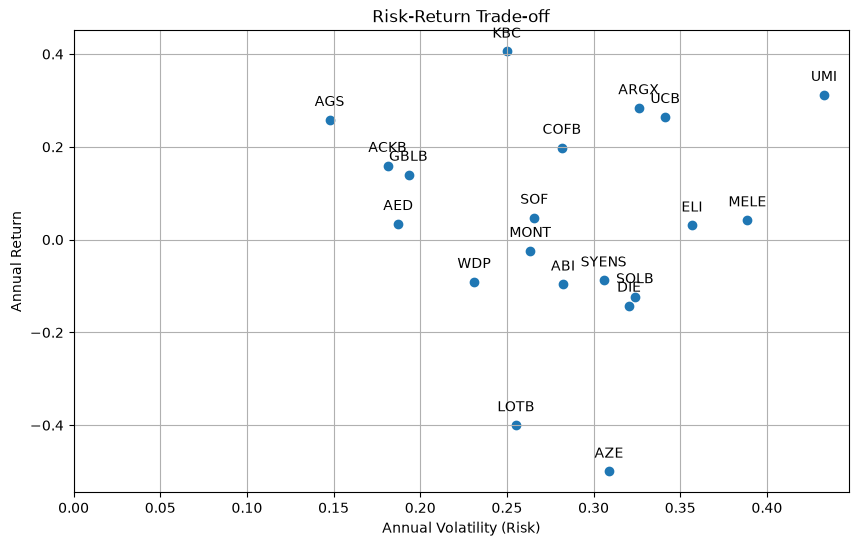

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(annual_vol, annual_returns)
# Add ticker labels to the points
for i, ticker in enumerate(tickers):
    plt.annotate(ticker, (annual_vol.iloc[i], annual_returns.iloc[i]), textcoords="offset points", xytext=(0,10), ha='center')

# Add labels and title
plt.title('Risk-Return Trade-off')
plt.xlabel('Annual Volatility (Risk)')
plt.ylabel('Annual Return')
plt.xlim(left=0) # Set x-axis limit to start at 0

plt.grid(True)
plt.show()

### Unconstrained Efficient Frontier

Constraints:
- Sum of weights = 1
- Expected returns >=0

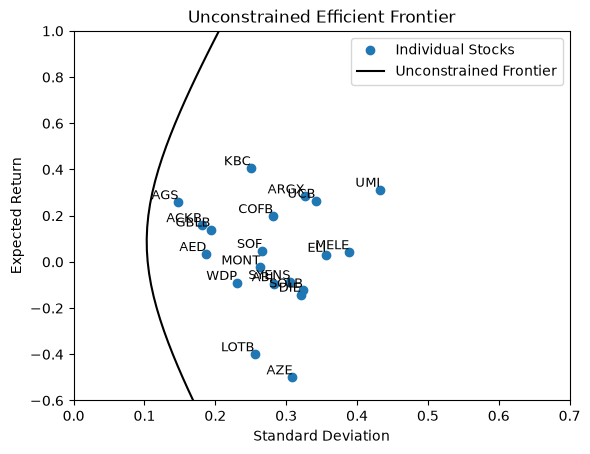

In [ ]:
# Unconstrained Efficient Frontier for a range of target returns, we solve for portfolio weights that minimize variance without constraints on short sales.
target_returns = np.arange(-1, 3, 0.05)
efficient_frontier_weights = []
portfolio_returns = []
portfolio_std_devs = []

# Assign annual_returns to ER and cov_matrix to V
ER = annual_returns
V = cov_matrix

for target_return in target_returns:
    constraints = [
        #Sum of weights =1
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        #ER > 0
        {'type': 'eq', 'fun': lambda w: np.dot(w, ER) - target_return}
    ]

    objective = lambda w: np.dot(w.T, np.dot(V, w))
    result = minimize(objective, x0=np.ones(len(ER))/len(ER), constraints=constraints, method='SLSQP', options={'maxiter': 100000, 'ftol': 1e-9})

    efficient_frontier_weights.append(result.x)
    portfolio_returns.append(np.dot(ER, result.x))
    portfolio_std_devs.append(np.sqrt(np.dot(result.x.T, np.dot(V, result.x))))

efficient_frontier_weights = np.array(efficient_frontier_weights).T

# Plot
plt.figure()
plt.plot(np.sqrt(np.diag(cov_matrix)), annual_returns, 'o', label='Individual Stocks')
#text labels
for i, ticker in enumerate(tickers):
    plt.text(annual_vol.iloc[i], annual_returns.iloc[i], ticker, fontsize=9, ha='right', va='bottom') # Use annual_vol.iloc and annual_returns.iloc

plt.xlim(left=0,right=0.7)
plt.ylim(bottom=-0.6,top=1)

#Unconstrained frontier
plt.plot(portfolio_std_devs, portfolio_returns, 'k', label='Unconstrained Frontier')
plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Unconstrained Efficient Frontier')
plt.legend()
plt.show()

### Optimal portfolios

#### Minimum Variance

This code calculates the weights of the minimum variance portfolio for the unconstrained case.

This portfolio represents the combination of assets that has the lowest possible risk (volatility) without considering returns.

In [ ]:
constraints_min_var = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
result_min_var = minimize(objective, x0=np.ones(len(ER))/len(ER), constraints=constraints_min_var, method='SLSQP')
weights_min_var = result_min_var.x
ret_min_var = np.dot(ER, weights_min_var)
std_min_var = np.sqrt(np.dot(weights_min_var.T, np.dot(V, weights_min_var)))

In [ ]:
print(f"Expected Return: {ret_min_var:.2%}")
print(f"Volatility: {std_min_var:.2%}")

Expected Return: 8.91%
Volatility: 10.32%


In [ ]:
w_min_var = pd.DataFrame({
    'Ticker': tickers,
    'Weight': weights_min_var
})
w_min_var['Weight']=w_min_var['Weight'].round(4)
w_min_var


,Ticker,Weight
0,ABI,0.1762
1,AED,0.1616
2,AGS,0.3081
3,MONT,0.1741
4,AZE,0.0175
5,GBLB,0.1134
6,ACKB,0.0241
7,ARGX,0.2028
8,COFB,-0.2209
9,DIE,0.0224


#### Tangency Portfolio

The tangency portfolio is the portfolio on the efficient frontier that has the highest Sharpe ratio.

It represents the optimal portfolio for an investor who can borrow or lend at the risk-free rate.

In [ ]:
def neg_sharpe(w):
    port_ret = np.dot(w, ER)
    port_std = np.sqrt(np.dot(w.T, np.dot(V, w)))
    return -(port_ret - rf) / port_std

constraints_tangency = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}

# Add bounds for weights between -1 and 1
bounds = tuple((-1, 1) for _ in range(len(ER)))

result_tangency = minimize(neg_sharpe, x0=np.ones(len(ER))/len(ER), constraints=constraints_tangency, bounds=bounds, method='SLSQP')
weights_tangency = result_tangency.x
ret_tangency = np.dot(ER, weights_tangency)
std_tangency = np.sqrt(np.dot(weights_tangency.T, np.dot(V, weights_tangency)))

In [ ]:
print(f"Expected Return: {ret_tangency:.2%}")
print(f"Volatility: {std_tangency:.2%}")

Expected Return: 171.69%
Volatility: 33.60%


In [ ]:
w_tangency = pd.DataFrame({
    'Ticker': tickers,
    'Weight': weights_tangency
})
w_tangency['Weight']=w_tangency['Weight'].round(4)
w_tangency

,Ticker,Weight
0,ABI,-0.2848
1,AED,0.2646
2,AGS,1.0000
3,MONT,0.4293
4,AZE,-0.6298
5,GBLB,1.0000
6,ACKB,-0.5896
7,ARGX,0.4337
8,COFB,0.4378
9,DIE,-0.3937


Note: Because of our implementation with linear constraints, the tangency portfolio requires leverage in order to achieve its repartition.
We should implement a quadratic constraint:
-1 < w < +1.


### Final plot

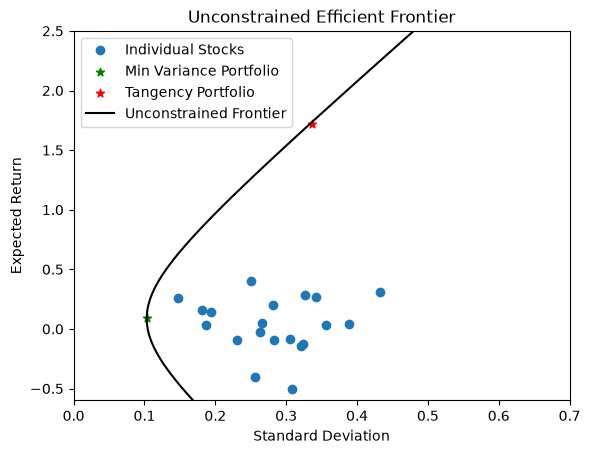

In [ ]:
# Plot
plt.figure()
plt.plot(np.sqrt(np.diag(cov_matrix)), annual_returns, 'o', label='Individual Stocks')
plt.scatter(std_min_var, ret_min_var, color='green', marker='*', label='Min Variance Portfolio')
plt.scatter(std_tangency, ret_tangency, color='red', marker='*', label='Tangency Portfolio')
#Unconstrained frontier
plt.plot(portfolio_std_devs, portfolio_returns, 'k', label='Unconstrained Frontier')

plt.xlim(left=0,right=0.7)
plt.ylim(bottom=-0.6,top=2.5)


plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Unconstrained Efficient Frontier')
plt.legend()
plt.show()

## 3. Constrained efficient frontier (Long only)


Constraints:

- Sum of weights = 1
- Expected returns >=0
- No short sales (w>=0)

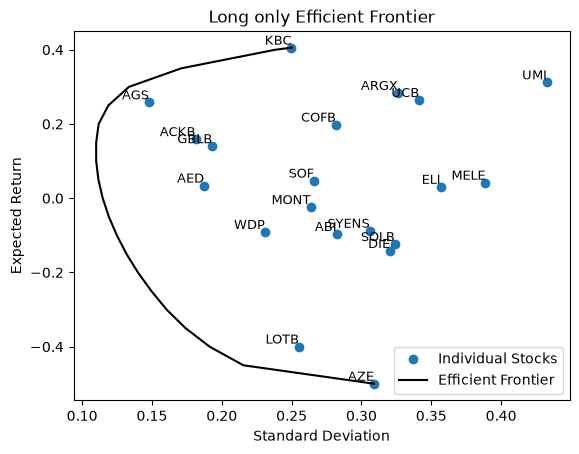

In [ ]:
# Constrained Efficient Frontier (Long only)
target_returns_constrained = np.arange(-0.6, 0.6, 0.05)
efficient_weights_constrained = []
portfolio_returns_constrained = []
portfolio_std_constrained = []

# Reinitialize efficient_frontier_weights as a list
efficient_frontier_weights = []

for target_return in target_returns_constrained:
    constraints = [
        #Sum of weights =1
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        #ER > 0
        {'type': 'eq', 'fun': lambda w: np.dot(w, ER) - target_return},
        #W >= 0
        {'type': 'ineq', 'fun': lambda w: w},
        ]

    objective = lambda w: np.dot(w.T, np.dot(V, w))
    result = minimize(objective, x0=np.ones(len(ER))/len(ER), constraints=constraints, method='SLSQP', options={'maxiter': 100000, 'ftol': 1e-9})

    efficient_weights_constrained.append(result.x)
    portfolio_returns_constrained.append(np.dot(ER, result.x))
    portfolio_std_constrained.append(np.sqrt(np.dot(result.x.T, np.dot(V, result.x))))

efficient_weights_constrained = np.array(efficient_weights_constrained).T

# Plot
plt.figure()
plt.plot(np.sqrt(np.diag(cov_matrix)), annual_returns, 'o', label='Individual Stocks')
#text labels
for i, ticker in enumerate(tickers):
    plt.text(annual_vol.iloc[i], annual_returns.iloc[i], ticker, fontsize=9, ha='right', va='bottom') # Use annual_vol.iloc and annual_returns.iloc

#Constrained frontier
plt.plot(portfolio_std_constrained, portfolio_returns_constrained, 'black', label='Efficient Frontier')
plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Long only Efficient Frontier')
plt.legend()
plt.show()

### Optimal Portfolios

#### Minimum Variance

In [ ]:
constraints_min_var_constrained = [
    {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},  # Somme des poids = 1
    {'type': 'ineq', 'fun': lambda w: w}             # Poids >= 0
]
objective = lambda w: np.dot(w.T, np.dot(V, w))  # Minimiser la variance

result_min_var_constrained = minimize(objective,
    x0=np.ones(len(ER)) / len(ER),
    constraints=constraints_min_var_constrained,
    method='SLSQP')

weights_min_var_constrained = result_min_var_constrained.x
ret_min_var_constrained = np.dot(ER, weights_min_var_constrained)
std_min_var_constrained = np.sqrt(np.dot(weights_min_var_constrained.T, np.dot(V, weights_min_var_constrained)))

In [ ]:
print(f"Expected Return: {ret_min_var_constrained:.2%}")
print(f"Volatility: {std_min_var_constrained:.2%}")

Expected Return: 12.74%
Volatility: 10.98%


In [ ]:
w_min_var_constrained = pd.DataFrame({
    'Ticker': tickers,
    'Weight': weights_min_var_constrained
})
w_min_var_constrained['Weight']=w_min_var_constrained['Weight'].round(4)
w_min_var_constrained.sort_values(by='Weight', ascending=False)

,Ticker,Weight
2,AGS,0.3313
7,ARGX,0.1737
1,AED,0.1317
5,GBLB,0.1104
0,ABI,0.0714
10,ELI,0.0606
4,AZE,0.0387
12,LOTB,0.0324
18,UMI,0.0289
14,SOF,0.0209


#### Tangency portfolio

In [ ]:

constraints_tangency_constrained = [
    {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},  # Somme des poids = 1
    {'type': 'ineq', 'fun': lambda w: w}             # Poids >= 0
]

result_tangency_constrained = minimize(
    neg_sharpe,
    x0=np.ones(len(ER)) / len(ER),
    constraints=constraints_tangency_constrained,
    method='SLSQP'
)

weights_tangency_constrained = result_tangency_constrained.x
ret_tangency_constrained = np.dot(ER, weights_tangency_constrained)
std_tangency_constrained = np.sqrt(np.dot(weights_tangency_constrained.T, np.dot(V, weights_tangency_constrained)))


In [ ]:
print(f"Expected Return: {ret_tangency_constrained:.2%}")
print(f"Volatility: {std_tangency_constrained:.2%}")

Expected Return: 30.04%
Volatility: 13.37%


In [ ]:
w_tangency_constrained = pd.DataFrame({
    'Ticker': tickers,
    'Weight': weights_tangency_constrained
})
w_tangency_constrained['Weight']=w_tangency_constrained['Weight'].round(4)
w_tangency_constrained.sort_values(by='Weight', ascending=False)

,Ticker,Weight
2,AGS,0.4998
11,KBC,0.2275
7,ARGX,0.2102
18,UMI,0.0626
0,ABI,-0.0000
17,UCB,-0.0000
16,SYENS,0.0000
15,SOLB,0.0000
14,SOF,0.0000
13,MELE,0.0000


### Final plot

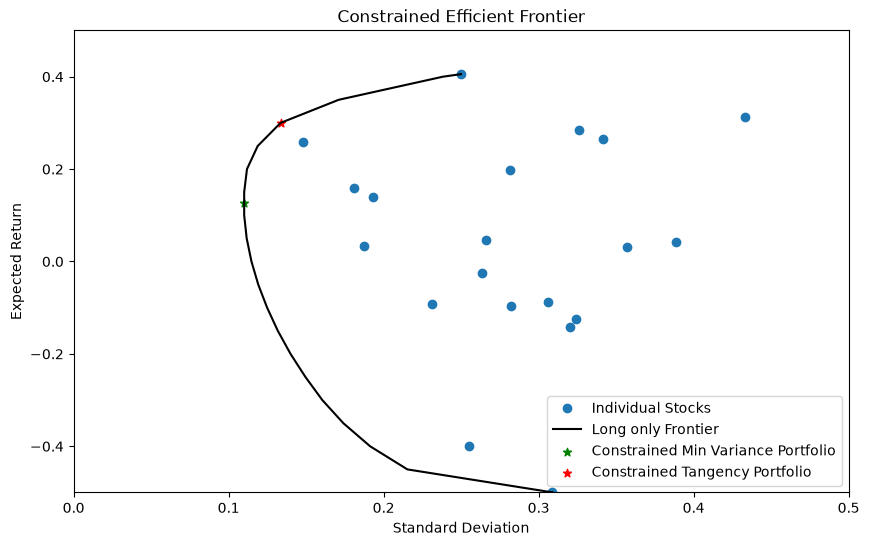

In [ ]:
plt.figure(figsize=(10, 6))
#Indiviodual stocks
plt.plot(np.sqrt(np.diag(cov_matrix)), annual_returns, 'o', label='Individual Stocks')
#Efficient Frontier
plt.plot(portfolio_std_constrained, portfolio_returns_constrained, 'black', label='Long only Frontier')
#Portfolios
plt.scatter(std_min_var_constrained, ret_min_var_constrained, color='green', marker='*', label='Constrained Min Variance Portfolio')
plt.scatter(std_tangency_constrained, ret_tangency_constrained, color='red', marker='*', label='Constrained Tangency Portfolio')

plt.xlim(left=0,right=0.5)
plt.ylim(bottom=-0.5,top=0.5)
plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Constrained Efficient Frontier')
plt.legend(loc='lower right')
plt.show()

##

---




## 4. Bonus: 5-Asset Long-Only Portfolio

#### Minimum Variance Portfolio

To complete this bonus question, we solved each problem individually rather than using a unified model. The new constraint introduced quadratic elements that we could not implement within our modeling framework, preventing us from using a unified approach.

In [ ]:
# Minimum Variance Portfolio with a maximum of 5 assets (Long only)

constraints_min_var_5_assets = [
    {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},  # Sum of weights = 1
    {'type': 'ineq', 'fun': lambda w: w},             # Weights >= 0
    # Constraint for maximum 5 non-zero weights - adjusted tolerance and added a penalty term
    {'type': 'ineq', 'fun': lambda w: 5 - np.sum(w > 1e-5)} # Adjusted tolerance for "zero" weights
]

objective = lambda w: np.dot(w.T, np.dot(V, w))  # Minimize variance

# Initial guess for weights: uniform distribution among a subset of assets
# Select 5 assets with highest individual Sharpe Ratios for the initial guess - refined
initial_guess_tickers = sharp_ratios.nlargest(5).index.tolist()
x0 = np.zeros(len(ER))
# Distribute weight equally among the top 5 for the initial guess
for ticker in initial_guess_tickers:
    x0[tickers.get_loc(ticker)] = 1.0 / 5.0

# Add a small random perturbation to help the optimizer
x0 = x0 + np.random.rand(len(ER)) * 0.001
x0 = x0 / np.sum(x0) # Normalize the initial guess

result_min_var_5_assets = minimize(objective,
    x0=x0, # Use the calculated initial guess
    constraints=constraints_min_var_5_assets,
    method='SLSQP',
    options={'maxiter': 100000, 'ftol': 1e-10}) # Increased maxiter and reduced ftol


weights_min_var_5_assets = result_min_var_5_assets.x
ret_min_var_5_assets = np.dot(ER, weights_min_var_5_assets)
std_min_var_5_assets = np.sqrt(np.dot(weights_min_var_5_assets.T, np.dot(V, weights_min_var_5_assets)))

In [ ]:
print(f"\nExpected Return: {ret_min_var_5_assets:.2%}")
print(f"Volatility: {std_min_var_5_assets:.2%}")


Expected Return: 12.87%
Volatility: 10.99%


In [ ]:
w_min_var_5_assets = pd.DataFrame({
    'Ticker': tickers,
    'Weight': weights_min_var_5_assets
})
w_min_var_5_assets['Weight'] = w_min_var_5_assets['Weight'].round(4)
display(w_min_var_5_assets.sort_values(by='Weight', ascending=False).head(9))

,Ticker,Weight
2,AGS,0.3363
7,ARGX,0.1653
1,AED,0.1474
5,GBLB,0.1305
0,ABI,0.0604
10,ELI,0.0567
4,AZE,0.0389
12,LOTB,0.0350
18,UMI,0.0296


#### Tangency Portfolio

In [ ]:
def neg_sharpe(w):
    port_ret = np.dot(w, ER)
    port_std = np.sqrt(np.dot(w.T, np.dot(V, w)))
    # Add a small epsilon to the standard deviation to avoid division by zero
    return -(port_ret - rf) / (port_std + 1e-9)

constraints_tangency_5_assets = [
    {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},  # Sum of weights = 1
    {'type': 'ineq', 'fun': lambda w: w},             # Weights >= 0
    # Constraint for maximum 5 non-zero weights - adjusted tolerance
    {'type': 'ineq', 'fun': lambda w: 5 - np.sum(w > 1e-5)} # Adjusted tolerance for "zero" weights
]

# Initial guess for weights: uniform distribution among the 5 assets with highest individual Sharpe Ratios
initial_guess_tickers_tangency = sharp_ratios.nlargest(5).index.tolist()
x0_tangency = np.zeros(len(ER))
for ticker in initial_guess_tickers_tangency:
    x0_tangency[tickers.get_loc(ticker)] = 1.0 / 5.0

result_tangency_5_assets = minimize(neg_sharpe,
    x0=x0_tangency, # Use the calculated initial guess
    constraints=constraints_tangency_5_assets,
    method='SLSQP',
    options={'maxiter': 100000, 'ftol': 1e-10}) # Increased maxiter and reduced ftol

weights_tangency_5_assets = result_tangency_5_assets.x
ret_tangency_5_assets = np.dot(ER, weights_tangency_5_assets)
std_tangency_5_assets = np.sqrt(np.dot(weights_tangency_5_assets.T, np.dot(V, weights_tangency_5_assets)))

In [ ]:
print(f"\nExpected Return: {ret_tangency_5_assets:.2%}")
print(f"Volatility: {std_tangency_5_assets:.2%}")


Expected Return: 30.04%
Volatility: 13.37%


In [ ]:
w_tangency_5_assets = pd.DataFrame({
    'Ticker': tickers,
    'Weight': weights_tangency_5_assets
})
w_tangency_5_assets['Weight'] = w_tangency_5_assets['Weight'].round(4)
display(w_tangency_5_assets.sort_values(by='Weight', ascending=False).head(5))



,Ticker,Weight
2,AGS,0.4999
11,KBC,0.2274
7,ARGX,0.2101
18,UMI,0.0625
0,ABI,0.0000


As our Tangency portfolio contained only 4 assets, it's logical that this question will provide the same portfolio.